# Лабораторная работа № 2. Клиент XML-RPC

## 1. Подключение

In [8]:
import xmlrpc.client as client
import pickle
from html import escape
from datetime import datetime, timedelta
from PIL import Image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def show_table(title, columns, rows):
    display(
        {'text/html': f'<h3 style="margin: 18px 0 10px; font-size: 20px; font-weight: 600;">{escape(title)}</h3>'},
        raw=True
    )

    if rows:
        table = pd.DataFrame(rows, columns=columns)

        display(
            table.style
            .hide(axis='index')
            .set_properties(**{
                'white-space': 'pre-line',
                'vertical-align': 'top'
            })
        )
    else:
        print('Записей не найдено.')


def format_person(person):
    if isinstance(person, dict):
        person = [person[field] for field in ('Surname', 'Name', 'Patronym', 'Birth')]

    if isinstance(person, (list, tuple)):
        return f'{person[0]} {person[1]} {person[2]} ({person[3]})'

    return str(person)


def blacklist_result_rows(person, result):
    status = result['status']

    if status == 'yes':
        result_text = format_person(result['data'])

    elif status == 'similar':
        matches = list(dict.fromkeys(
            format_person(match) for match in result['data']
        ))
        result_text = '\n'.join(matches)

    else:
        result_text = format_person(result['data'])

    return [(format_person(person), status, result_text)]


server = client.ServerProxy('http://localhost:8008')
stats = client.ServerProxy('http://localhost:8018')

print('Основной сервер: http://localhost:8008/RPC2')
print('Сервер статистики: http://localhost:8018/RPC2')

Основной сервер: http://localhost:8008/RPC2
Сервер статистики: http://localhost:8018/RPC2


## 2. Проверка по чёрному списку


In [10]:
people = [
    ('Иванов', 'Иван', 'Иванович', '22.03.1989'),
    ('Иванав', 'Иван', 'Иванович', '22.03.1989'),
    ('Петров', 'Петор', 'Петрович', '07.08.1985'),
    ('Светлый', 'Михаил', 'Викторовач', '13.02.1992'),
    ('Иванов', 'Иван', 'Иванович', '23.03.1989'),
    ('Смирнов', 'Алексей', 'Сергеевич', '10.10.1990'),
]
rows = []
for person in people:
    rows.extend(blacklist_result_rows(person, server.black_list_check_full(*person)))
show_table('Проверка ФИО', ['Введённые данные', 'Статус', 'Результат'], rows)

Проверка ФИО

Введённые данные,Статус,Результат
Иванов Иван Иванович (22.03.1989),yes,Иванов Иван Иванович (22.03.1989)
Иванав Иван Иванович (22.03.1989),similar,Иванов Иван Иванович (22.03.1989) Иванов Ивано Иванович (22.03.1989) Ивана Ивано Иванович (22.03.1989)
Петров Петор Петрович (07.08.1985),similar,Петров Петр Петрович (07.08.1985)
Светлый Михаил Викторовач (13.02.1992),similar,Светлый Михаил Викторович (13.02.1992)
Иванов Иван Иванович (23.03.1989),no,Иванов Иван Иванович (23.03.1989)
Смирнов Алексей Сергеевич (10.10.1990),no,Смирнов Алексей Сергеевич (10.10.1990)


## 3. Бинаризация и оценка облачности


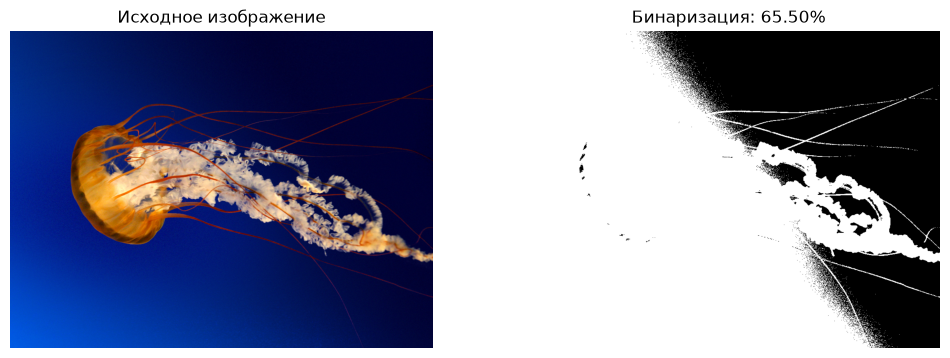

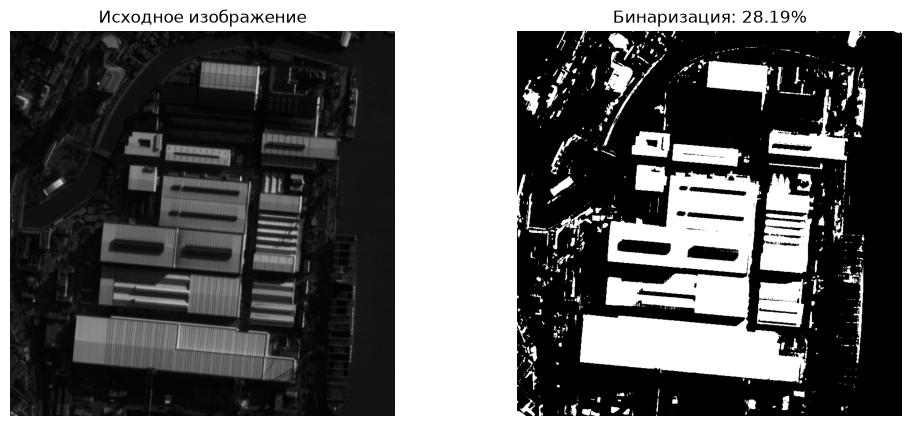

In [14]:
def estimate_cloudiness(image, threshold):
    result = server.estimate_cloudiness(client.Binary(pickle.dumps(image)), threshold)
    return pickle.loads(result['image'].data), result['percent']


def show_before_after(original, binary, percent, cmap=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    axes[0].imshow(original, cmap=cmap)
    axes[0].set_title('Исходное изображение')
    axes[1].imshow(binary, cmap=cmap, vmin=0, vmax=255)
    axes[1].set_title(f'Бинаризация: {percent:.2f}%')
    for axis in axes:
        axis.axis('off')
    plt.show()


img_arr = np.array(Image.open('Jellyfish.jpg').convert('RGB'))
img_bmp_arr = np.array(Image.open('11.bmp').convert('L'))
results = []
for image, label, cmap in [(img_arr, 'RGB', None), (img_bmp_arr, 'Монохромное', 'gray')]:
    binary, percent = estimate_cloudiness(image, 30)
    results.append((label, 128, f'{percent:.2f}%'))
    show_before_after(image, binary, percent, cmap)

## 4. Получение журнала событий


In [15]:
def get_events(function_type='', time_from='', time_to=''):
    try:
        return stats.get_log(function_type, time_from, time_to, True)
    except ConnectionRefusedError:
        return []


def show_events(title, events):
    rows = [
        (
            datetime.fromisoformat(event['timestamp']).strftime('%d.%m.%Y %H:%M:%S.%f'),
            event['event_type']
        )
        for event in events
    ]

    show_table(
        title,
        ['Время события', 'Операция'],
        rows
    )


show_events(
    'Все операции',
    get_events()
)

date_string = "15.10.2026 13:00:00"
format_string = "%d.%m.%Y %H:%M:%S"
time_from = datetime.strptime(date_string, format_string)

date_string = "16.10.2026 13:00:00"
time_to = datetime.strptime(date_string, format_string)

show_events(
    'Проверки ФИО за последние 10 минут',
    get_events(
        'black_list_check_full',
        time_from.isoformat(timespec='microseconds'),
        time_to.isoformat(timespec='microseconds')
    )
)

Все операции

Время события,Операция
05.10.2026 13:04:07.032098,black_list_check_full
05.10.2026 13:07:49.523398,black_list_check_full
05.10.2026 13:07:49.531941,black_list_check_full
05.10.2026 13:07:49.591525,black_list_check_full
05.10.2026 13:07:49.623415,black_list_check_full
05.10.2026 13:07:49.657344,black_list_check_full
05.10.2026 13:07:49.702807,black_list_check_full
05.10.2026 13:07:49.715898,black_list_check_full
05.10.2026 13:07:49.751292,black_list_check_full
05.10.2026 13:07:49.797872,black_list_check_full


Проверки ФИО за последние 10 минут

Время события,Операция
15.10.2026 19:00:30.281027,black_list_check_full
15.10.2026 19:00:33.332967,black_list_check_full
15.10.2026 19:00:36.392727,black_list_check_full
15.10.2026 19:00:39.461139,black_list_check_full
15.10.2026 19:00:42.503088,black_list_check_full
15.10.2026 19:00:45.540947,black_list_check_full
15.10.2026 19:03:14.842728,black_list_check_full
15.10.2026 19:03:17.894316,black_list_check_full
15.10.2026 19:03:20.965037,black_list_check_full
15.10.2026 19:03:24.025676,black_list_check_full


## 5. Проверка работоспособности при выключенном сервере

In [ ]:
try:
    result = server.black_list_check_full(*people[0])

    print("Клиент успешно подключился к серверу.")
    print("Сервер работает корректно.")
    print("Результат вызова:")
    data = result['data']
    print(f"{data['Surname']} {data['Name']} {data['Patronym']} ({data['Birth']}) — {result['status']}")

except Exception as error:
    print("Ошибка взаимодействия клиента и сервера:")
    print(error)